# Logistic regression — choosing the Newton initial guess
### Goal : predict whether GNN initialization will save at least one Newton iteration compared with the standard initialization.

Important: RMSE against the future ground truth is unavailable at inference time. The first model below is a deployable-feature baseline using Re, dt and optionally other known-before-solve features. newton_standard, newton_gnn, iterations_saved and convergence flags are never input features. Splits are grouped by Reynolds configuration to avoid leakage between adjacent timesteps. For geometry generalization, use a geometry/group identifier and hold out entire geometries.

In [82]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             balanced_accuracy_score, confusion_matrix,
                             classification_report, RocCurveDisplay)

DATA_PATH = Path(r"C:\Users\giovanni\gnn\outputs\CONFIGURATION_PAPER_REYNOLDS\statistical_analysis\gnn_newton_analysis_dataset.csv")
df = pd.read_csv(DATA_PATH)
print(df.shape)
display(df.head())


(3100, 21)


,k,time,dt,newton_standard,newton_gnn,standard_converged,gnn_converged,rmse_u,rmse_v,rmse_p,...,baseline_rmse_velocity,baseline_rmse_p,Re,initial_guess,bdf_order,iterations_saved,both_converged,iteration_reduction_percent,velocity_rmse_gain,pressure_rmse_gain
0,6,0.12,0.02,9.0,9.0,True,True,0.028569,0.020090,2.521426,...,0.112834,1.202242,200,gnn,2,0.0,True,0.000000,3.230664,0.476810
1,7,0.14,0.02,9.0,10.0,True,True,0.037591,0.022822,0.670898,...,0.108283,3.843428,200,gnn,2,-1.0,True,-11.111111,2.462266,5.728779
2,8,0.16,0.02,10.0,9.0,True,True,0.020697,0.013486,0.055383,...,0.104652,0.203044,200,gnn,2,1.0,True,10.000000,4.236483,3.666148
3,9,0.18,0.02,10.0,9.0,True,True,0.020161,0.013829,0.063512,...,0.100343,0.225011,200,gnn,2,1.0,True,10.000000,4.104319,3.542842
4,10,0.20,0.02,11.0,10.0,True,True,0.019076,0.013229,0.055170,...,0.095053,0.210942,200,gnn,2,1.0,True,9.090909,4.094624,3.823495


## Feature engineering

Let's start with the following features:
\begin{equation}
z_k=
\begin{bmatrix}
Re\\
\Delta t_k\\
\Delta t_k/\Delta t_{k-1}\\
N_{\mathrm{previous}}\\
\overline N_{\mathrm{last5}}\\
\sigma(N_{\mathrm{last5}})
\end{bmatrix}
\end{equation}

In [83]:
import numpy as np
import pandas as pd

df_selector = df.copy()

df_selector = df_selector.sort_values(
    ["Re", "k"]
).reset_index(drop=True)

# ----------------------------------------
# 1. Time-step features
# ----------------------------------------

df_selector["dt_previous"] = (
    df_selector.groupby("Re")["dt"].shift(1)
)

df_selector["dt_ratio"] = (
    df_selector["dt"] / df_selector["dt_previous"]
)

# ----------------------------------------
# 2. Previous Newton iterations
# ----------------------------------------

df_selector["newton_previous"] = (
    df_selector.groupby("Re")["newton_standard"].shift(1)
)

# ----------------------------------------
# 3. Rolling statistics (previous 5 steps)
# ----------------------------------------

grouped = df_selector.groupby("Re")["newton_standard"]

df_selector["newton_mean_last5"] = grouped.transform(
    lambda x: x.shift(1).rolling(
        window=5,
        min_periods=5
    ).mean()
)

df_selector["newton_std_last5"] = grouped.transform(
    lambda x: x.shift(1).rolling(
        window=5,
        min_periods=5
    ).std(ddof=0)
)

# ----------------------------------------
# 4. Target
# ----------------------------------------

df_selector["target"] = (
    df_selector["iterations_saved"] > 0
).astype(int)

In [84]:
features = [
    "Re",
    "dt",
    "dt_ratio",
    "newton_previous",
    "newton_mean_last5",
    "newton_std_last5"
]

columns = [
    "Re",
    "k",
    "time",
    *[f for f in features if f != "Re"],
    "target",
    "iterations_saved",
    "newton_standard",
    "newton_gnn"
]

df_train = df_selector.loc[
    (df_selector["k"] >= 6)
    & df_selector["both_converged"],
    columns
].copy()

df_train = df_train.replace(
    [np.inf, -np.inf], np.nan
).dropna(subset=features)

print("Training dataset shape:", df_train.shape)

display(df_train.head())

from pathlib import Path

output_path = (
    Path(r"C:\Users\giovanni\gnn\outputs")
    / "CONFIGURATION_PAPER_REYNOLDS"
    / "statistical_analysis"
    / "gnn_selector_dataset.csv"
)

df_train.to_csv(output_path, index=False)

print("Saved:", output_path)

Training dataset shape: (3055, 12)


,Re,k,time,dt,dt_ratio,newton_previous,newton_mean_last5,newton_std_last5,target,iterations_saved,newton_standard,newton_gnn
5,40,11,0.22,0.02,1.0,5.0,5.2,0.4,0,0.0,5.0,5.0
6,40,12,0.24,0.02,1.0,5.0,5.2,0.4,0,0.0,5.0,5.0
7,40,13,0.26,0.02,1.0,5.0,5.0,0.0,0,0.0,5.0,5.0
8,40,14,0.28,0.02,1.0,5.0,5.0,0.0,0,0.0,5.0,5.0
9,40,15,0.30,0.02,1.0,5.0,5.0,0.0,0,0.0,5.0,5.0


Saved: C:\Users\giovanni\gnn\outputs\CONFIGURATION_PAPER_REYNOLDS\statistical_analysis\gnn_selector_dataset.csv


## Train/validation/test split

In [85]:
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 68

# First split: 70% train, 30% temporary
train, temp = train_test_split(
    df_train,
    test_size=0.30,
    random_state=SEED,
    shuffle=True,
    stratify=df_train["Re"]
)

# Second split: 15% validation, 15% test
val, test = train_test_split(
    temp,
    test_size=0.50,
    random_state=SEED,
    shuffle=True,
    stratify=temp["Re"]
)

# Reset indices
train = train.reset_index(drop=True)
val = val.reset_index(drop=True)
test = test.reset_index(drop=True)

print(f"Training:   {len(train)} samples")
print(f"Validation: {len(val)} samples")
print(f"Test:       {len(test)} samples")

Training:   2138 samples
Validation: 458 samples
Test:       459 samples


## Training

In [86]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

features = [
    "Re",
    "dt",
    "dt_ratio",
    "newton_previous",
    "newton_mean_last5",
    "newton_std_last5"
]

model_linear = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000, random_state=68)
)

model_linear.fit(train[features], train["target"])


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Re','dt','dt_ratio','newton_previous','newton_mean_last5', 'newton_std_last5']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


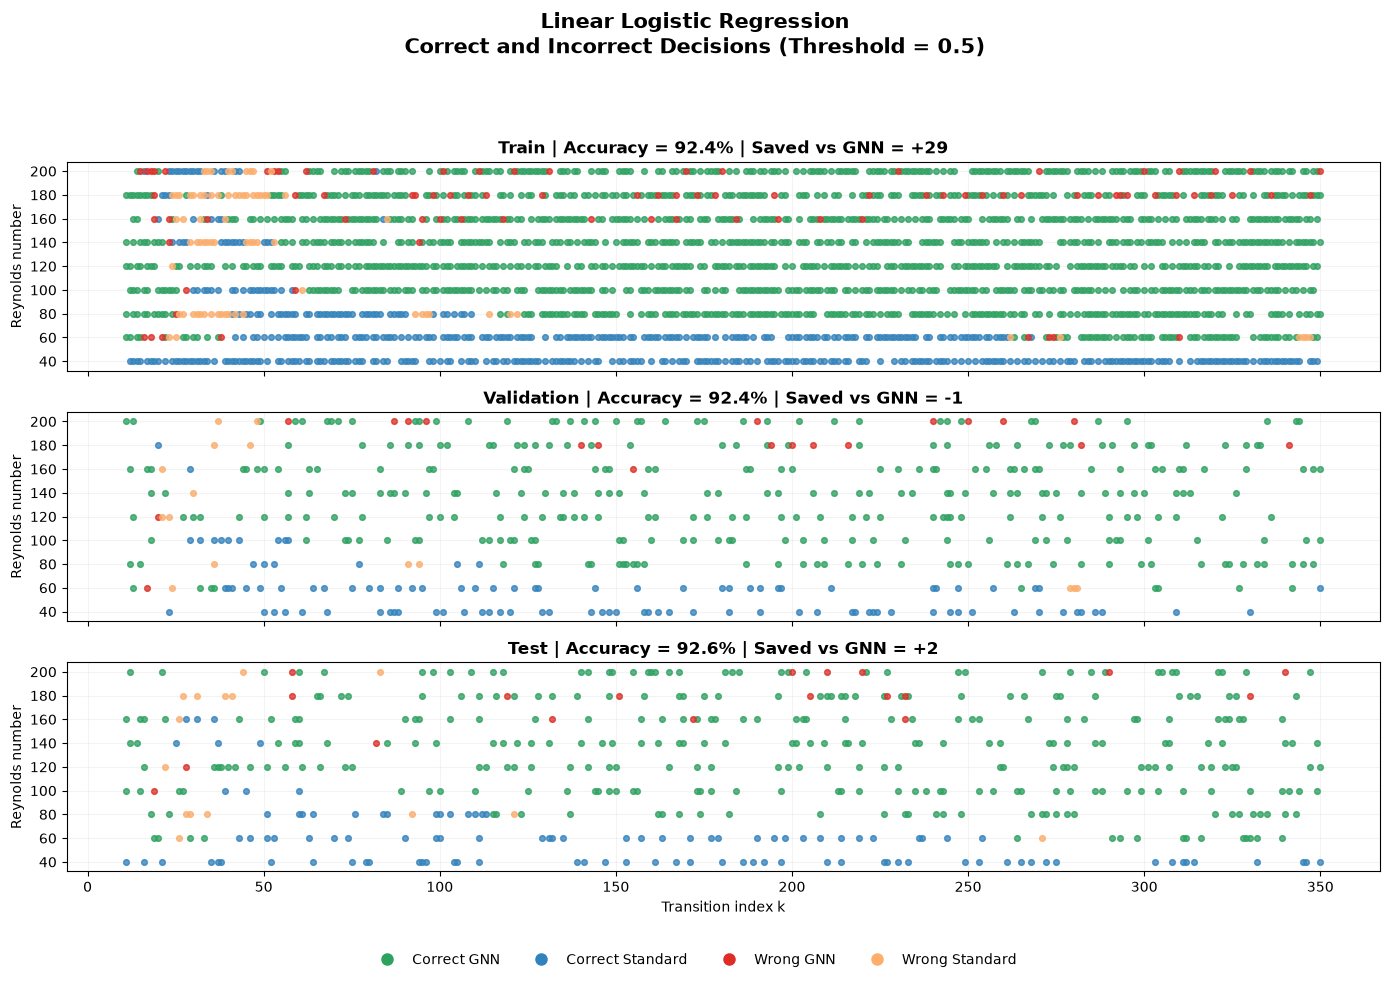

In [87]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

threshold = 0.5

datasets = {
    "Train": train,
    "Validation": val,
    "Test": test
}

colors = {
    "Correct GNN": "#2ca25f",
    "Correct Standard": "#3182bd",
    "Wrong GNN": "#de2d26",
    "Wrong Standard": "#fdae6b"
}

fig, axes = plt.subplots(
    3, 1, figsize=(14, 10),
    sharex=True, sharey=True
)

for ax, (name, data) in zip(axes, datasets.items()):

    d = data.copy()

    d["p_gnn"] = model_linear.predict_proba(d[features])[:, 1]
    d["use_gnn"] = d["p_gnn"] >= threshold

    d["decision"] = np.select(
        [
            d["use_gnn"] & (d["iterations_saved"] > 0),
            ~d["use_gnn"] & (d["iterations_saved"] <= 0),
            d["use_gnn"] & (d["iterations_saved"] <= 0),
            ~d["use_gnn"] & (d["iterations_saved"] > 0)
        ],
        [
            "Correct GNN",
            "Correct Standard",
            "Wrong GNN",
            "Wrong Standard"
        ],
        default="Unknown"
    )

    for category, color in colors.items():
        subset = d[d["decision"] == category]

        ax.scatter(
            subset["k"], subset["Re"],
            c=color, s=17, alpha=0.8,
            rasterized=True
        )

    accuracy = (d["use_gnn"] == d["target"]).mean()

    extra_saved = np.where(
        ~d["use_gnn"],
        -d["iterations_saved"],
        0
    ).sum()

    ax.set_title(
        f"{name} | Accuracy = {accuracy:.1%} | "
        f"Saved vs GNN = {extra_saved:+.0f}",
        fontsize=12, fontweight="bold"
    )

    ax.set_ylabel("Reynolds number")
    ax.set_yticks(sorted(df_train["Re"].unique()))
    ax.grid(alpha=0.15)

axes[-1].set_xlabel("Transition index k")

handles = [
    Line2D(
        [0], [0], marker="o", linestyle="None",
        color=color, markersize=8, label=label
    )
    for label, color in colors.items()
]

fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4, frameon=False
)

fig.suptitle(
    f"Linear Logistic Regression\n"
    f"Correct and Incorrect Decisions (Threshold = {threshold})",
    fontsize=15, fontweight="bold"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])
plt.show()


## Hyperparemeter tuning of the threshold

In [88]:

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

C_values = np.logspace(-3, 3, 13)
class_weights = [None, "balanced"]
thresholds = np.linspace(0.05, 0.95, 91)

results = []
best_accuracy = -1

for C in C_values:
    for class_weight in class_weights:

        candidate = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=C,
                class_weight=class_weight,
                max_iter=10000,
                random_state=68
            )
        )

        candidate.fit(train[features], train["target"])

        probabilities = candidate.predict_proba(val[features])[:, 1]
        targets = val["target"].to_numpy()

        for threshold in thresholds:
            predictions = probabilities >= threshold
            accuracy = (predictions == targets).mean()

            results.append({
                "C": C,
                "class_weight": str(class_weight),
                "threshold": threshold,
                "accuracy": accuracy
            })

            if accuracy > best_accuracy:
                best_accuracy = accuracy
                best_model = candidate
                best_threshold = threshold

results_df = pd.DataFrame(results)

print(f"Best validation accuracy: {best_accuracy:.2%}")
print(f"Best threshold: {best_threshold:.2f}")
print(best_model.named_steps["logisticregression"])


Best validation accuracy: 94.10%
Best threshold: 0.51
LogisticRegression(C=np.float64(0.01), max_iter=10000, random_state=68)


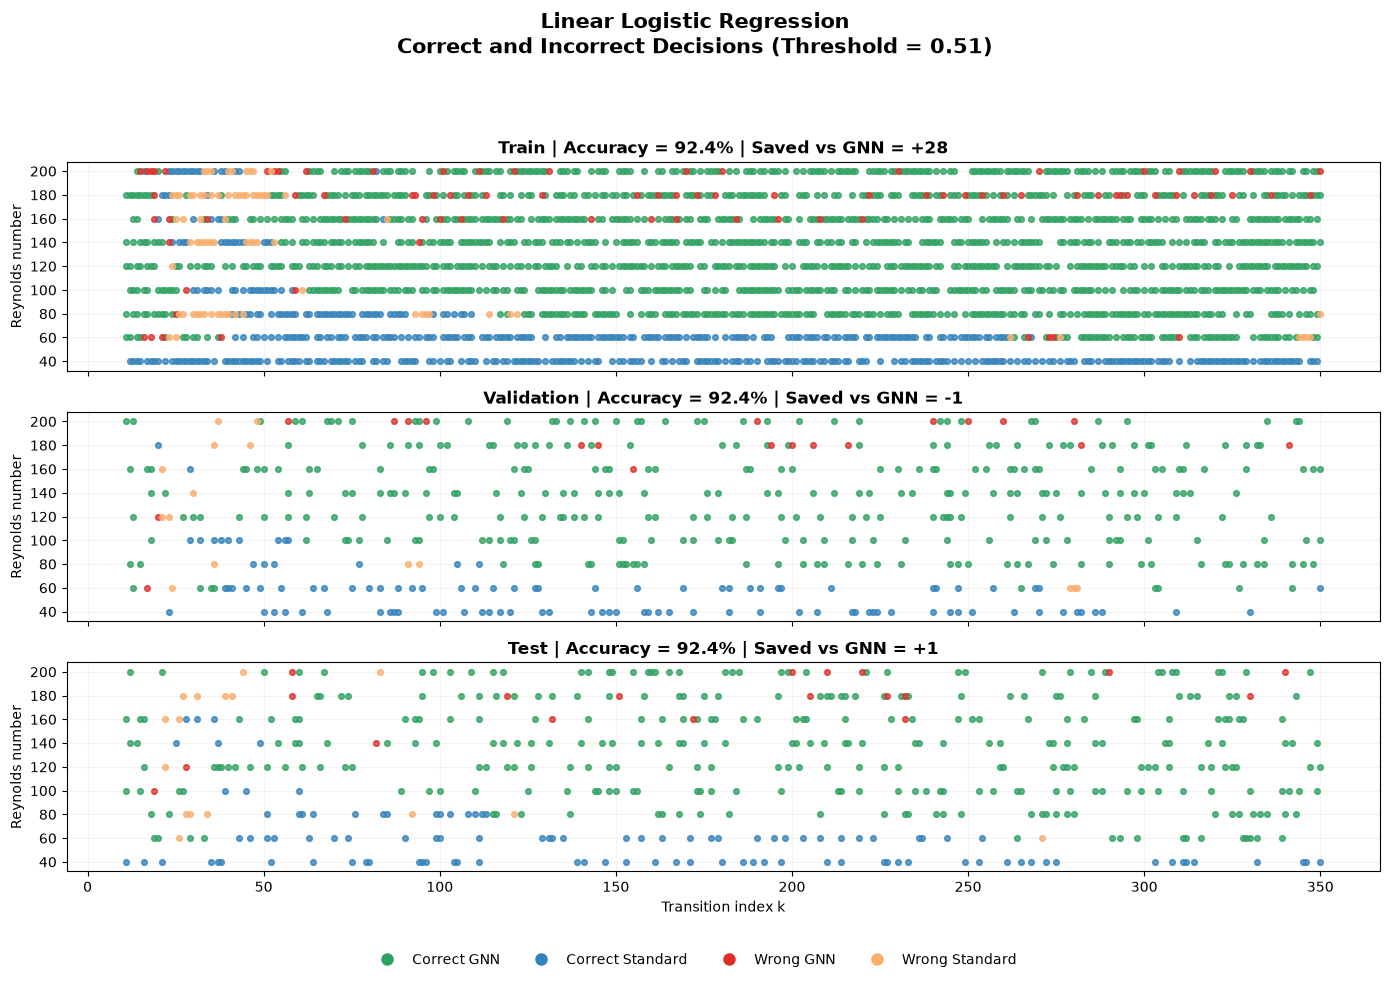

In [89]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

threshold = 0.51

datasets = {
    "Train": train,
    "Validation": val,
    "Test": test
}

colors = {
    "Correct GNN": "#2ca25f",
    "Correct Standard": "#3182bd",
    "Wrong GNN": "#de2d26",
    "Wrong Standard": "#fdae6b"
}

fig, axes = plt.subplots(
    3, 1, figsize=(14, 10),
    sharex=True, sharey=True
)

for ax, (name, data) in zip(axes, datasets.items()):

    d = data.copy()

    d["p_gnn"] = model_linear.predict_proba(d[features])[:, 1]
    d["use_gnn"] = d["p_gnn"] >= threshold

    d["decision"] = np.select(
        [
            d["use_gnn"] & (d["iterations_saved"] > 0),
            ~d["use_gnn"] & (d["iterations_saved"] <= 0),
            d["use_gnn"] & (d["iterations_saved"] <= 0),
            ~d["use_gnn"] & (d["iterations_saved"] > 0)
        ],
        [
            "Correct GNN",
            "Correct Standard",
            "Wrong GNN",
            "Wrong Standard"
        ],
        default="Unknown"
    )

    for category, color in colors.items():
        subset = d[d["decision"] == category]

        ax.scatter(
            subset["k"], subset["Re"],
            c=color, s=17, alpha=0.8,
            rasterized=True
        )

    accuracy = (d["use_gnn"] == d["target"]).mean()

    extra_saved = np.where(
        ~d["use_gnn"],
        -d["iterations_saved"],
        0
    ).sum()

    ax.set_title(
        f"{name} | Accuracy = {accuracy:.1%} | "
        f"Saved vs GNN = {extra_saved:+.0f}",
        fontsize=12, fontweight="bold"
    )

    ax.set_ylabel("Reynolds number")
    ax.set_yticks(sorted(df_train["Re"].unique()))
    ax.grid(alpha=0.15)

axes[-1].set_xlabel("Transition index k")

handles = [
    Line2D(
        [0], [0], marker="o", linestyle="None",
        color=color, markersize=8, label=label
    )
    for label, color in colors.items()
]

fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4, frameon=False
)

fig.suptitle(
    f"Linear Logistic Regression\n"
    f"Correct and Incorrect Decisions (Threshold = {threshold})",
    fontsize=15, fontweight="bold"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])
plt.show()


# Limitations

## Test on cylinder stretch configuration

In [95]:

import numpy as np
import pandas as pd
from scipy.io import loadmat

path = r"C:\Users\giovanni\.comsol\v64\llmatlab\stationary_gnn_comparison.mat"

results = loadmat(
    path, squeeze_me=True, struct_as_record=False
)["results"]

# Physical parameters
U, rho, mu = 1.0, 1.0, 1e-3
a, b = 0.05, 0.1

Re = rho * U * (2 * np.sqrt(a * b)) / mu

features = [
    "Re",
    "dt",
    "dt_ratio",
    "newton_previous",
    "newton_mean_last5",
    "newton_std_last5"
]

# Load Newton results
df_geometry = pd.DataFrame({
    "Re": Re,
    "k": np.asarray(results.k).ravel(),
    "time": np.asarray(results.t_target).ravel(),
    "dt": np.asarray(results.dt).ravel(),
    "newton_standard": np.asarray(results.standard_iterations).ravel().astype(np.int64),
    "newton_gnn": np.asarray(results.gnn_iterations).ravel().astype(np.int64),
    "standard_converged": np.asarray(results.standard_converged).ravel().astype(bool),
    "gnn_converged": np.asarray(results.gnn_converged).ravel().astype(bool)
})

df_geometry = df_geometry.iloc[:349].copy()
df_geometry = df_geometry.sort_values("k").reset_index(drop=True)

# Temporal features
df_geometry["dt_previous"] = df_geometry["dt"].shift(1)
df_geometry["dt_ratio"] = df_geometry["dt"] / df_geometry["dt_previous"]

# Newton history
previous = df_geometry["newton_standard"].shift(1)

df_geometry["newton_previous"] = previous
df_geometry["newton_mean_last5"] = previous.rolling(5).mean()
df_geometry["newton_std_last5"] = previous.rolling(5).std(ddof=0)

# Target
df_geometry["iterations_saved"] = (
    df_geometry["newton_standard"] - df_geometry["newton_gnn"]
)

df_geometry["target"] = (
    df_geometry["iterations_saved"] > 0
).astype(int)

df_geometry["both_converged"] = (
    df_geometry["standard_converged"]
    & df_geometry["gnn_converged"]
)

# Filter valid transitions
df_geometry = (
    df_geometry.loc[
        (df_geometry["k"] >= 6) & df_geometry["both_converged"]
    ]
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=features)
    .reset_index(drop=True)
)

# Checks
assert np.array_equal(
    df_geometry["iterations_saved"].to_numpy(),
    df_geometry["newton_standard"].to_numpy()
    - df_geometry["newton_gnn"].to_numpy()
)

assert df_geometry[features].notna().all().all()

print(f"Re = {Re:.2f}")
print(f"Dataset shape: {df_geometry.shape}")
print(f"GNN beneficial: {df_geometry['target'].mean():.2%}")

display(df_geometry.head())
display(df_geometry.tail())


Re = 141.42
Dataset shape: (344, 16)
GNN beneficial: 14.53%


,Re,k,time,dt,newton_standard,newton_gnn,standard_converged,gnn_converged,dt_previous,dt_ratio,newton_previous,newton_mean_last5,newton_std_last5,iterations_saved,target,both_converged
0,141.421356,7,0.14,0.02,9,10,True,True,0.02,1.0,9.0,8.6,0.489898,-1,0,True
1,141.421356,8,0.16,0.02,9,9,True,True,0.02,1.0,9.0,8.8,0.400000,0,0,True
2,141.421356,9,0.18,0.02,9,10,True,True,0.02,1.0,9.0,9.0,0.000000,-1,0,True
3,141.421356,10,0.20,0.02,10,10,True,True,0.02,1.0,9.0,9.0,0.000000,0,0,True
4,141.421356,11,0.22,0.02,10,10,True,True,0.02,1.0,10.0,9.2,0.400000,0,0,True


,Re,k,time,dt,newton_standard,newton_gnn,standard_converged,gnn_converged,dt_previous,dt_ratio,newton_previous,newton_mean_last5,newton_std_last5,iterations_saved,target,both_converged
339,141.421356,346,6.70225,0.02,7,9,True,True,0.02,1.0,7.0,7.0,0.0,-2,0,True
340,141.421356,347,6.72225,0.02,7,9,True,True,0.02,1.0,7.0,7.0,0.0,-2,0,True
341,141.421356,348,6.74225,0.02,7,9,True,True,0.02,1.0,7.0,7.0,0.0,-2,0,True
342,141.421356,349,6.76225,0.02,7,9,True,True,0.02,1.0,7.0,7.0,0.0,-2,0,True
343,141.421356,350,6.78225,0.02,7,9,True,True,0.02,1.0,7.0,7.0,0.0,-2,0,True


In [96]:

probabilities = best_model.predict_proba(df_geometry[features])[:, 1]
predictions = probabilities >= best_threshold

accuracy = (predictions == df_geometry["target"].to_numpy()).mean()

selected_iterations = np.where(
    predictions,
    df_geometry["newton_gnn"],
    df_geometry["newton_standard"]
)

standard_total = df_geometry["newton_standard"].sum()
gnn_total = df_geometry["newton_gnn"].sum()
classifier_total = selected_iterations.sum()

print(f"Threshold: {best_threshold:.2f}")
print(f"Accuracy: {accuracy:.2%}")
print(f"GNN usage: {predictions.mean():.2%}")
print()
print(f"Always Standard: {standard_total:.0f}")
print(f"Always GNN: {gnn_total:.0f}")
print(f"Classifier: {classifier_total:.0f}")
print()
print(f"Saved vs Standard: {standard_total - classifier_total:+.0f}")
print(f"Saved vs GNN: {gnn_total - classifier_total:+.0f}")


Threshold: 0.51
Accuracy: 16.86%
GNN usage: 97.67%

Always Standard: 2899
Always GNN: 3138
Classifier: 3132

Saved vs Standard: -233
Saved vs GNN: +6


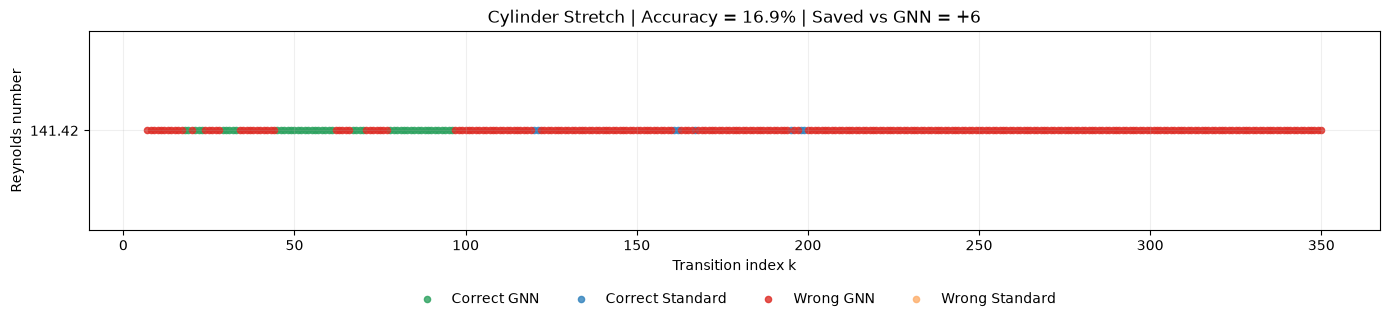

In [97]:

import matplotlib.pyplot as plt

d = df_geometry.copy()
d["p_gnn"] = probabilities
d["use_gnn"] = predictions

d["decision"] = np.select(
    [
        d["use_gnn"] & (d["target"] == 1),
        ~d["use_gnn"] & (d["target"] == 0),
        d["use_gnn"] & (d["target"] == 0),
        ~d["use_gnn"] & (d["target"] == 0) == False
    ],
    [
        "Correct GNN",
        "Correct Standard",
        "Wrong GNN",
        "Wrong Standard"
    ],
    default="Unknown"
)

colors = {
    "Correct GNN": "#2ca25f",
    "Correct Standard": "#3182bd",
    "Wrong GNN": "#de2d26",
    "Wrong Standard": "#fdae6b"
}

fig, ax = plt.subplots(figsize=(14, 3.5))

for category, color in colors.items():
    subset = d[d["decision"] == category]

    ax.scatter(
        subset["k"],
        subset["Re"],
        c=color,
        s=20,
        alpha=0.8,
        label=category
    )

ax.set_xlabel("Transition index k")
ax.set_ylabel("Reynolds number")
ax.set_yticks([Re])
ax.set_title(
    f"Cylinder Stretch | Accuracy = {accuracy:.1%} | "
    f"Saved vs GNN = {gnn_total - classifier_total:+.0f}"
)

ax.grid(alpha=0.2)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=4,
    frameon=False
)

plt.tight_layout()
plt.show()


This might be a good approach to reduce this type of effects but clearly the current model is not able to understand a priori if the solution will likely converge to a stationary solution.